<a href="https://colab.research.google.com/github/kunapareddysriram2007-cmyk/Deep_Learning/blob/main/Skill_7_Model_Artefact_Lifecycle_Colab_Simplified.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model Artefact Lifecycle
### Architecture → Trained Checkpoint → ONNX Graph → TensorRT Engine

**Skill:** Deep Learning with Accelerated Computing  
**Model:** Ultralytics YOLO11n (`yolo11n.pt`)  
**Platform:** Google Colab with an optional NVIDIA GPU

This practical shows how the same pretrained model moves through four important stages:

**Architecture → `.pt` checkpoint → `.onnx` graph → `.engine` TensorRT engine**

The TensorRT stage is optional because it depends on the GPU, CUDA, driver and TensorRT software available in the current Colab runtime.

## What is a model artefact?

A **model artefact** is a saved representation produced while developing or deploying a machine-learning model.

Different stages use different formats:

- **Architecture:** defines the network structure.
- **`.pt` checkpoint:** stores the trained model and learned parameters in the PyTorch/Ultralytics ecosystem.
- **`.onnx` graph:** represents the computation in a more portable format.
- **`.engine` TensorRT engine:** is an NVIDIA-optimized inference representation.

We use different formats because training, portability and fast deployment have different requirements.

# 1. Environment Setup

First we install only the libraries needed for this practical and create one directory for all generated artefacts.

In [1]:
import sys
import subprocess
from pathlib import Path

# PyTorch is normally already available in Colab.
packages = ["ultralytics", "onnx", "onnxruntime", "opencv-python", "pillow"]

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + packages)

ARTEFACT_DIR = Path("/content/model_artefacts")
ARTEFACT_DIR.mkdir(parents=True, exist_ok=True)

print("Artefact directory:", ARTEFACT_DIR)

Artefact directory: /content/model_artefacts


In [2]:
import subprocess
import torch
import ultralytics
import onnxruntime as ort

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version used by PyTorch:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU: Not available - CPU inference will be used.")

print("ONNX Runtime:", ort.__version__)
print("ONNX Runtime providers:", ort.get_available_providers())

print("\n--- nvidia-smi ---")
try:
    subprocess.run(["nvidia-smi"], check=False)
except FileNotFoundError:
    print("nvidia-smi is not available in this runtime.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python: 3.13.16
PyTorch: 2.14.1+cu130
Ultralytics: 8.4.218
CUDA available: True
CUDA version used by PyTorch: 13.0
GPU: Tesla T4
ONNX Runtime: 1.32.0
ONNX Runtime providers: ['AzureExecutionProvider', 'CPUExecutionProvider']

--- nvidia-smi ---


# 2. Model Architecture

An **architecture** is the blueprint of a neural network: its layers, connections and operations.

YOLO11n is the small/nano member of the YOLO11 family. We use the pretrained model, so we do not train a model from scratch.

The important distinction is:

- **Architecture = how the network is built**
- **Parameters/weights = learned numerical values inside that architecture**

In [3]:
from ultralytics import YOLO

MODEL_NAME = "yolo11n.pt"
model = YOLO(MODEL_NAME)

print("Loaded model:", MODEL_NAME)
print("Task:", model.task)

# Ultralytics prints the model summary.
model.info()

Loaded model: yolo11n.pt
Task: detect
YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.7 GFLOPs


(181, 2624080, 0, 6.6733184)

The summary shows the network structure and parameter count. The architecture itself is not the learned knowledge; the learned knowledge is stored in the model parameters.

For this practical, we do not need to inspect individual tensors.

# 3. Trained Checkpoint (`.pt`)

A pretrained checkpoint is a saved model after training.

For YOLO11n, the `.pt` file belongs to the PyTorch/Ultralytics ecosystem and contains the information needed to recreate the trained model and use its learned parameters.

This is **not training from scratch**. We are starting with a model that already has learned weights.

In [4]:
import shutil

checkpoint_path = ARTEFACT_DIR / "yolo11n.pt"

# Keep a copy of the pretrained checkpoint in our artefact directory.
source_path = Path(MODEL_NAME)

if source_path.exists():
    shutil.copy2(source_path, checkpoint_path)
else:
    # This is normally unnecessary because YOLO() downloads the checkpoint.
    model = YOLO(MODEL_NAME)
    shutil.copy2(MODEL_NAME, checkpoint_path)

print("Checkpoint saved to:", checkpoint_path)
print("Size: %.2f MB" % (checkpoint_path.stat().st_size / (1024**2)))

Checkpoint saved to: /content/model_artefacts/yolo11n.pt
Size: 5.35 MB


In [5]:
# Reload the saved checkpoint.
reloaded_model = YOLO(str(checkpoint_path))

print("Reloaded:", checkpoint_path.name)
print("Task:", reloaded_model.task)
reloaded_model.info()

Reloaded: yolo11n.pt
Task: detect
YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.7 GFLOPs


(181, 2624080, 0, 6.6733184)

### Run one practical detection

The sample image is downloaded automatically, so the notebook does not depend on a file uploaded from your computer.

In [6]:
from urllib.request import urlretrieve

sample_image = ARTEFACT_DIR / "sample.jpg"
sample_url = "https://ultralytics.com/images/bus.jpg"

if not sample_image.exists():
    urlretrieve(sample_url, sample_image)

prediction = reloaded_model.predict(
    source=str(sample_image),
    imgsz=640,
    conf=0.25,
    device=0 if torch.cuda.is_available() else "cpu",
    save=False,
    verbose=False
)[0]

checkpoint_result = ARTEFACT_DIR / "checkpoint_prediction.jpg"
prediction.save(filename=str(checkpoint_result))

print("Detections:", len(prediction.boxes))
print("Result saved to:", checkpoint_result)

Detections: 5
Result saved to: /content/model_artefacts/checkpoint_prediction.jpg


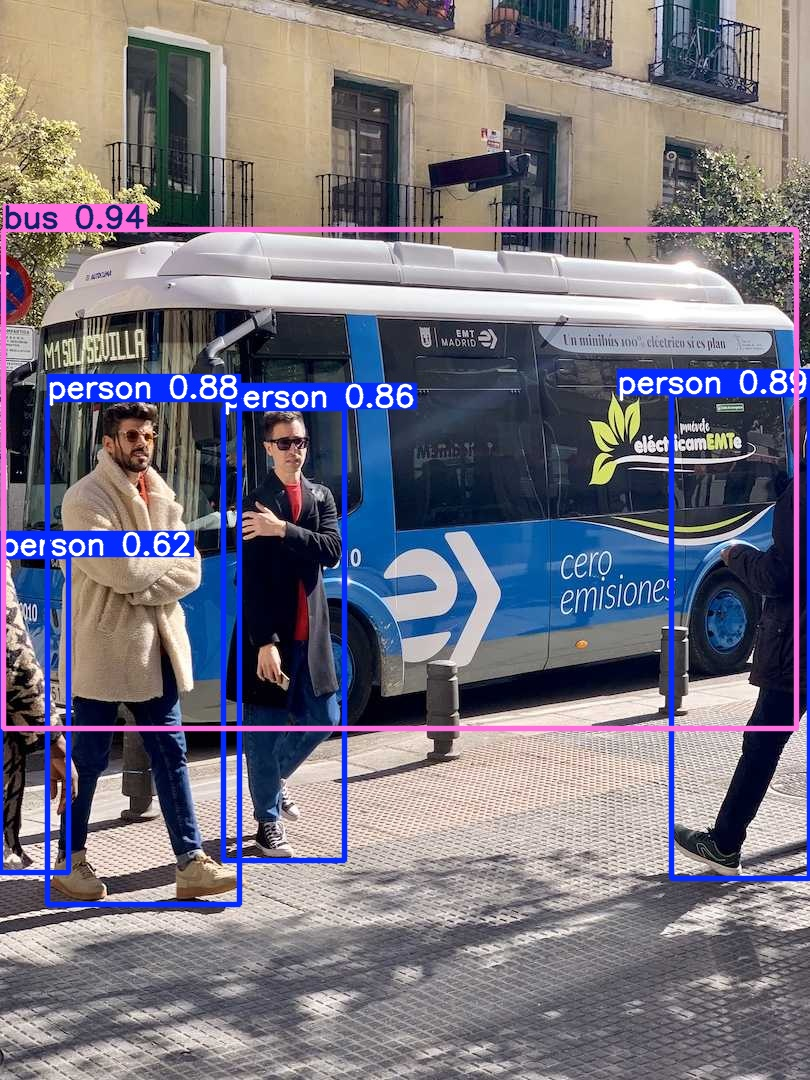

In [7]:
from IPython.display import display
from PIL import Image

display(Image.open(checkpoint_result))

# 4. ONNX Graph (`.onnx`)

**ONNX (Open Neural Network Exchange)** provides a portable representation of model computation.

We export the same YOLO11n model to ONNX. Then we validate the graph and inspect its inputs and outputs.

The exported ONNX output is a **model computation graph**, not automatically a list of final human-readable detections. YOLO detection requires model-specific post-processing.

In [8]:
onnx_path = ARTEFACT_DIR / "yolo11n.onnx"

exported_path = reloaded_model.export(
    format="onnx",
    imgsz=640,
    dynamic=False,
    simplify=False
)

# Ultralytics returns the exported path.
exported_path = Path(exported_path)

if exported_path.resolve() != onnx_path.resolve():
    shutil.copy2(exported_path, onnx_path)

print("ONNX file:", onnx_path)
print("Size: %.2f MB" % (onnx_path.stat().st_size / (1024**2)))

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs

PyTorch: starting from '/content/model_artefacts/yolo11n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (5.4 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: export success ✅ 0.9s, saved as '/content/model_artefacts/yolo11n.onnx' (10.2 MB)

Export complete (1.4s)
Results saved to /content/model_artefacts/yolo11n.onnx
Predict:         yolo predict task=detect model=/content/model_artefacts/yolo11n.onnx imgsz=640 
Validate:        yolo val task=detect model=/content/model_artefacts/yolo11n.onnx imgsz=640  
Visualize:       https://netron.app
ONNX file: /content/model_artefacts/yolo11n.onnx
Size: 10.21 MB


In [9]:
import onnx

onnx_model = onnx.load(str(onnx_path))
onnx.checker.check_model(onnx_model)

print("ONNX graph validation: PASSED")
print("Graph nodes:", len(onnx_model.graph.node))

def shape_of(value_info):
    dims = []
    for dim in value_info.type.tensor_type.shape.dim:
        if dim.HasField("dim_value"):
            dims.append(dim.dim_value)
        elif dim.HasField("dim_param"):
            dims.append(dim.dim_param)
        else:
            dims.append("?")
    return dims

print("\nInputs:")
for x in onnx_model.graph.input:
    print(" ", x.name, shape_of(x))

print("\nOutputs:")
for x in onnx_model.graph.output:
    print(" ", x.name, shape_of(x))

ONNX graph validation: PASSED
Graph nodes: 355

Inputs:
  images [1, 3, 640, 640]

Outputs:
  output0 [1, 84, 8400]


### ONNX Runtime inference

ONNX Runtime executes the ONNX graph. We first run the graph directly with the available execution provider.

The small preprocessing step below uses Ultralytics' `LetterBox` so the image preparation matches YOLO's expected 640×640 input format. We then run the ONNX graph with ONNX Runtime.

The direct ORT output is the **raw model output**. For final boxes and labels, we let Ultralytics handle YOLO-specific post-processing in the next cell.

In [10]:
import numpy as np
import cv2
from ultralytics.data.augment import LetterBox

image_bgr = cv2.imread(str(sample_image))
letterbox = LetterBox(new_shape=(640, 640), auto=False, stride=32)

# LetterBox expects an image and returns a YOLO-compatible resized/padded image.
processed_bgr = letterbox(image=image_bgr)
processed_rgb = cv2.cvtColor(processed_bgr, cv2.COLOR_BGR2RGB)

input_tensor = processed_rgb.transpose(2, 0, 1)[None].astype(np.float32) / 255.0

print("ORT input shape:", input_tensor.shape)

ORT input shape: (1, 3, 640, 640)


In [11]:
session = ort.InferenceSession(
    str(onnx_path),
    providers=ort.get_available_providers()
)

input_name = session.get_inputs()[0].name
ort_outputs = session.run(None, {input_name: input_tensor})

print("Execution provider:", session.get_providers()[0])
print("Number of outputs:", len(ort_outputs))

for i, output in enumerate(ort_outputs):
    print(f"Output {i}: shape={output.shape}, dtype={output.dtype}")

Execution provider: AzureExecutionProvider
Number of outputs: 1
Output 0: shape=(1, 84, 8400), dtype=float32


Loading /content/model_artefacts/yolo11n.onnx for ONNX Runtime inference...
requirements: Ultralytics requirement ['onnxruntime-gpu[cuda]'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 181ms
Prepared 1 package in 3.14s
Installed 1 package in 66ms
 + onnxruntime-gpu==1.32.0

requirements: AutoUpdate success ✅ 3.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Using ONNX Runtime 1.32.0 with CPUExecutionProvider
WARNING ⚠️ CUDA requested but CUDAExecutionProvider not available. Using CPU...
Final detections after YOLO post-processing: 5
Result saved to: /content/model_artefacts/onnx_prediction.jpg


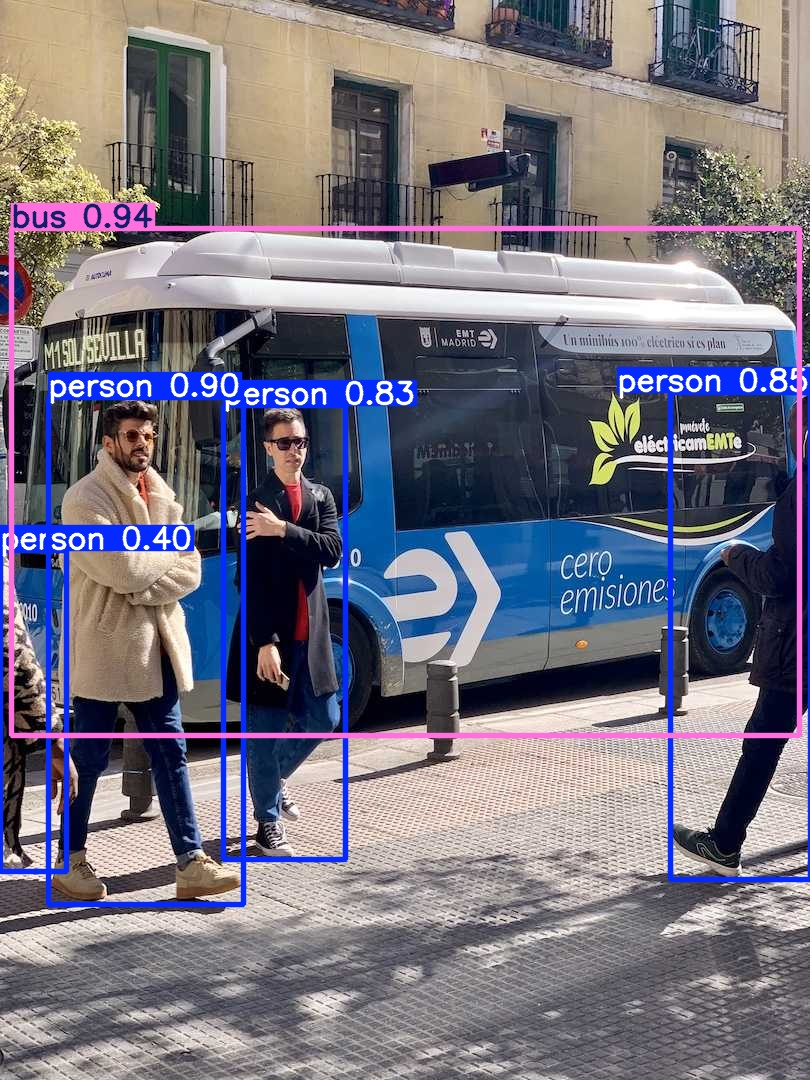

In [12]:
# Use the exported ONNX model through Ultralytics for YOLO-specific
# preprocessing and post-processing, then display the final detections.
onnx_model = YOLO(str(onnx_path))

onnx_prediction = onnx_model.predict(
    source=str(sample_image),
    imgsz=640,
    conf=0.25,
    device=0 if torch.cuda.is_available() else "cpu",
    save=False,
    verbose=False
)[0]

onnx_result = ARTEFACT_DIR / "onnx_prediction.jpg"
onnx_prediction.save(filename=str(onnx_result))

print("Final detections after YOLO post-processing:", len(onnx_prediction.boxes))
print("Result saved to:", onnx_result)

display(Image.open(onnx_result))

**Key idea:** PyTorch/Ultralytics and ONNX Runtime are different execution environments, but they can represent and execute the same learned model. ONNX is especially useful when a deployment environment does not need the original PyTorch training stack.

# 5. TensorRT Engine (`.engine`)

**TensorRT** is NVIDIA's inference optimization and runtime technology.

It can optimize a neural network for a specific NVIDIA GPU. One common optimization is **FP16**, which uses 16-bit floating-point values instead of 32-bit values. FP16 can reduce memory use and often improve inference speed on supported GPUs.

A TensorRT engine is more hardware/software dependent than an ONNX graph, so we only attempt this stage when a CUDA GPU and TensorRT package are actually available.

In [13]:
# Check TensorRT availability without installing a hard-coded TensorRT/CUDA version.
tensorrt_available = False
tensorrt_version = None

try:
    import tensorrt as trt
    tensorrt_available = True
    tensorrt_version = trt.__version__
except Exception:
    pass

print("CUDA GPU available:", torch.cuda.is_available())
print("TensorRT available:", tensorrt_available)

if tensorrt_available:
    print("TensorRT version:", tensorrt_version)
else:
    print("TensorRT is not available in this Colab runtime.")

CUDA GPU available: True
TensorRT available: False
TensorRT is not available in this Colab runtime.


In [14]:
engine_path = ARTEFACT_DIR / "yolo11n.engine"
engine_success = False

if torch.cuda.is_available() and tensorrt_available:
    print("Attempting TensorRT FP16 export...")
    try:
        exported_engine = reloaded_model.export(
            format="engine",
            imgsz=640,
            half=True,
            device=0
        )
        exported_engine = Path(exported_engine)

        if exported_engine.exists():
            if exported_engine.resolve() != engine_path.resolve():
                shutil.copy2(exported_engine, engine_path)

            engine_success = engine_path.exists()
            print("TensorRT engine export succeeded.")
            print("Engine:", engine_path)
        else:
            print("TensorRT export returned, but the engine file was not found.")
    except Exception as exc:
        print("TensorRT export could not be completed.")
        print("Reason:", exc)
else:
    print("TensorRT export skipped.")
    print("Reason: a compatible CUDA GPU and TensorRT package are both required.")

TensorRT export skipped.
Reason: a compatible CUDA GPU and TensorRT package are both required.


In [15]:
if engine_success:
    try:
        engine_model = YOLO(str(engine_path))

        engine_prediction = engine_model.predict(
            source=str(sample_image),
            imgsz=640,
            conf=0.25,
            device=0,
            save=False,
            verbose=False
        )[0]

        engine_result = ARTEFACT_DIR / "tensorrt_prediction.jpg"
        engine_prediction.save(filename=str(engine_result))

        print("TensorRT inference succeeded.")
        print("Detections:", len(engine_prediction.boxes))
        display(Image.open(engine_result))
    except Exception as exc:
        print("TensorRT engine was generated, but inference could not be completed.")
        print("Reason:", exc)
else:
    print("No TensorRT inference was run because no usable engine was generated.")

No TensorRT inference was run because no usable engine was generated.


# 6. Artefact Comparison

Each artefact has a different job. The `.engine` file is the most hardware-dependent representation.

In [16]:
from IPython.display import display, Markdown
import pandas as pd

comparison = pd.DataFrame([
    ["Architecture", "Model definition", "Defines the network structure", "Framework-dependent"],
    [".pt checkpoint", "Learned model + weights/metadata", "Training/reloading in PyTorch/Ultralytics", "PyTorch/Ultralytics ecosystem"],
    [".onnx graph", "Portable computation graph", "Cross-runtime model deployment", "Broad runtime support"],
    [".engine", "Optimized TensorRT engine", "Fast NVIDIA GPU inference", "Hardware/software dependent"],
], columns=["Artefact", "Purpose / contents", "Main use", "Portability"])

display(comparison)

print("\nGenerated file sizes:")
for path in sorted(ARTEFACT_DIR.iterdir()):
    if path.is_file() and path.suffix.lower() in {".pt", ".onnx", ".engine"}:
        print(f"{path.name:20s} {path.stat().st_size / (1024**2):8.2f} MB")

,Artefact,Purpose / contents,Main use,Portability
0,Architecture,Model definition,Defines the network structure,Framework-dependent
1,.pt checkpoint,Learned model + weights/metadata,Training/reloading in PyTorch/Ultralytics,PyTorch/Ultralytics ecosystem
2,.onnx graph,Portable computation graph,Cross-runtime model deployment,Broad runtime support
3,.engine,Optimized TensorRT engine,Fast NVIDIA GPU inference,Hardware/software dependent



Generated file sizes:
yolo11n.onnx            10.21 MB
yolo11n.pt               5.35 MB


# 7. Conclusion and Viva

## Lifecycle

```text
┌─────────────────────┐
│     Architecture    │
│  Network structure  │
└──────────┬──────────┘
           │ + learned weights
           ▼
┌─────────────────────┐
│  Trained Checkpoint │
│      yolo11n.pt     │
└──────────┬──────────┘
           │ export
           ▼
┌─────────────────────┐
│     ONNX Graph      │
│     yolo11n.onnx    │
└──────────┬──────────┘
           │ optimize for NVIDIA GPU
           ▼
┌─────────────────────┐
│  TensorRT Engine    │
│     yolo11n.engine  │
└──────────┬──────────┘
           ▼
     Optimized Inference
```

### What each stage does

1. **Architecture:** defines what the neural network looks like.
2. **`.pt`:** preserves the trained model in the PyTorch/Ultralytics ecosystem.
3. **`.onnx`:** provides a more portable computation representation.
4. **`.engine`:** optimizes inference for a compatible NVIDIA environment.

If TensorRT is unavailable, the lifecycle still remains valid through the ONNX stage; the engine stage simply cannot be demonstrated in that runtime.

## Viva Questions

**1. What is a model architecture?**  
It is the structure of a neural network: its layers, connections and operations.

**2. What is a checkpoint?**  
A saved representation of a trained model, including learned parameters and related model information.

**3. What are model weights?**  
Learned numerical values that allow the network to make useful predictions.

**4. Why use ONNX?**  
ONNX provides a portable representation that can be executed by different compatible runtimes.

**5. What is ONNX Runtime?**  
A runtime that executes ONNX models using available execution providers.

**6. What is TensorRT?**  
NVIDIA's inference optimization and runtime technology for supported NVIDIA hardware.

**7. Why is FP16 useful?**  
It can reduce memory use and improve inference speed on hardware that efficiently supports half precision.

**8. Is an ONNX model hardware-specific?**  
Generally it is much more portable than a TensorRT engine, although runtime and operator support still matter.

**9. Why can a TensorRT engine be hardware-dependent?**  
It is optimized and compiled for a particular NVIDIA software/hardware environment.

**10. Does a smaller or faster model automatically have better accuracy?**  
No. File size and inference speed do not by themselves prove accuracy.

In [17]:
print("=== Final Artefact Inventory ===")
print("Directory:", ARTEFACT_DIR)

for path in sorted(ARTEFACT_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name:28s} {path.stat().st_size / (1024**2):8.2f} MB")

print("\nPractical complete.")
print("TensorRT engine generated:", engine_success)

=== Final Artefact Inventory ===
Directory: /content/model_artefacts
checkpoint_prediction.jpg        0.35 MB
onnx_prediction.jpg              0.35 MB
sample.jpg                       0.13 MB
yolo11n.onnx                    10.21 MB
yolo11n.pt                       5.35 MB

Practical complete.
TensorRT engine generated: False
